# India City-wise Cost of Living Analysis Using Numbeo

**Project Domain:** Data Analytics  
**Data Source:** Numbeo  
**Tools & Technologies:** Python, Pandas, NumPy, Requests, BeautifulSoup, Matplotlib, Seaborn, Jupyter Notebook

## Business Problem

Individuals planning to relocate for employment, education, or personal reasons need to understand how living costs differ between cities. Comparing locations based only on salary or rent can provide an incomplete picture.
This project addresses the problem by analyzing city-level cost-of-living indexes and related indicators to help users compare locations more systematically. The analysis focuses on the cities available in the collected dataset rather than assuming that the results represent every city or state in India.

## Problem Statement
The cost of living varies across Indian cities due to differences in rent, grocery prices, restaurant expenses, and local purchasing power. Understanding these variations is essential for evaluating city-wise affordability and making informed financial decisions. This project analyzes Numbeo data to compare cost-of-living indicators across Indian cities, identify cities with higher and lower living costs, examine the relationship between rent and overall cost of living, and assess local purchasing power. The findings help individuals make informed decisions about relocation, budgeting, and selecting suitable cities to live in.

## Project Overview

The cost of living varies across Indian cities due to differences in housing, groceries, transportation, restaurants, and purchasing power. This project analyzes Numbeo data to compare cost-of-living indexes across Indian cities and examine how rent, grocery prices, restaurant prices, and local purchasing power vary.

Using Python, the project performs data collection, cleaning, exploratory data analysis (EDA), visualization, and insight generation to support data-driven comparisons between cities.

## Project Objectives

- Analyze cost-of-living indexes across Indian cities.
- Identify cities with the highest and lowest cost-of-living indexes.
- Compare rent indexes, grocery indexes, and restaurant price indexes.
- Examine differences in local purchasing power.
- Explore relationships between cost of living and purchasing power.
- Summarize key findings through charts and statistical analysis.
- Provide insights that can support preliminary budgeting and relocation decisions.

## Dataset Description

The project uses two related datasets collected from Numbeo:

**Dataset 1: City-wise Cost of Living Index**
- City and State/Region
- Cost of Living Index
- Rent Index
- Cost of Living Plus Rent Index
- Groceries Index
- Restaurant Price Index
- Local Purchasing Power Index

**Dataset 2: India National Price Data**
- Category
- Item
- Price
- Lower and upper price ranges
- Country
- Collection date

The city-wise dataset supports comparisons between locations, while the national price dataset provides item-level price information for India. These datasets are analyzed separately because city index values and national price values represent different types of measurements.

## Data Collection Methodology

The project uses Numbeo as its designated data source. The collected data is parsed into structured Pandas DataFrames for cleaning and analysis.

Automated data collection must comply with Numbeo's terms and applicable access requirements. Use automated extraction only with the required written permission, or use an authorized API method. Record the source and collection date to support transparency and reproducibility.

## Extracting Data from the Web

BeautifulSoup is used to parse the HTML content and identify the table containing cost-of-living information. The extraction process captures each item's category, name, displayed price, and available lower and upper price ranges. The extracted information is stored in a Pandas DataFrame for further cleaning and analysis.

In [34]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://en.wikipedia.org/wiki/States_and_union_territories_of_India"

headers = {
    "User-Agent": "IndiaCostAnalysisStudentProject/1.0"
}

response = requests.get(url, headers=headers, timeout=20)

print("Status code:", response.status_code)

if response.status_code == 200:
    soup = BeautifulSoup(response.text, "html.parser")

    tables = soup.find_all("table")

    print("Number of tables:", len(tables))

    for i, table in enumerate(tables[:5]):
        print(f"\nTABLE {i}")
        print(table.get_text(" ", strip=True)[:500])
else:
    print("Page could not be retrieved.")

Status code: 200
Number of tables: 13

TABLE 0
States and union territories of India Andhra Pradesh Arunachal Pradesh Assam Bihar Chhattisgarh National Capital Territory Goa Gujarat Haryana Himachal Pradesh Jammu and Kashmir Ladakh Jharkhand Karnataka Kerala Madhya Pradesh Maharashtra Manipur Meghalaya Mizoram Nagaland Odisha Punjab Rajasthan Sikkim Tamil Nadu Telangana Tripura Uttarakhand Uttar Pradesh West Bengal Andaman and Nicobar Islands Chandigarh Dadra and Nagar Haveli and Daman and Diu Lakshadweep Puducherry Category Federated states

TABLE 1
Politics of India Constitution Amendment Basic structure doctrine Fundamental Rights, Directive Principles, and Fundamental Duties Human rights Judicial review Taxation Government President of India ( List ) Droupadi Murmu Vice President of India ( List ) C. P. Radhakrishnan Prime Minister of India ( List ) Narendra Modi Cabinet Secretary T. V. Somanathan Ministries Ministers Departments and Agencies Secretaries Parliament Lok Sabha ( 18th

In [35]:

for i, table in enumerate(tables):
    headings = [
        th.get_text(" ", strip=True)
        for th in table.find_all("th")
    ]

    print(f"\nTable {i}")
    print(headings[:15])



Table 0
['States and union territories of India', 'Category', 'Location', 'Number', 'Populations', 'Areas', 'Government', 'Subdivisions']

Table 1
['Politics of India', '', '']

Table 2
['States and union territories of India ordered by']

Table 3
[]

Table 4
['State', 'ISO', 'Vehicle code', 'Zone', 'Capital', 'Largest city', 'Statehood', 'Population (2011) [ 30 ] [ 31 ]', 'Area (km 2 )', 'Official languages [ 32 ]', 'Additional official languages [ 32 ]', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar']

Table 5
['State [ 54 ]', 'ISO [ 55 ]', 'Vehicle code [ 56 ]', 'Zone [ 57 ]', 'Capital [ 54 ]', 'Largest city [ 58 ]', 'Established [ 59 ]', 'Population ( 2011 ) [ 60 ]', 'Area (km 2 ) [ 61 ]', 'Official languages [ 62 ]', 'Additional official languages [ 62 ]', 'Andaman and Nicobar Islands', 'Chandigarh', 'Dadra and Nagar Haveli and Daman and Diu', 'Delhi']

Table 6
['Map', 'State', 'Capital', 'Years', 'Present-day state(s)']

Table 7
['Name', 'Zone', 'Capital', 'Area', 'Begi

In [36]:

from io import StringIO

if response.status_code != 200:
    raise RuntimeError("The Wikipedia page was not retrieved successfully.")

html_tables = pd.read_html(StringIO(response.text))

print("Tables extracted:", len(html_tables))

for i, df in enumerate(html_tables):
    print(f"\nDataFrame {i}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


Tables extracted: 13

DataFrame 0
Shape: (8, 2)
Columns: ['States and union territories of India', 'States and union territories of India.1']


,States and union territories of India,States and union territories of India.1
0,Andhra Pradesh Arunachal Pradesh Assam Bihar C...,Andhra Pradesh Arunachal Pradesh Assam Bihar C...
1,Category,Federated states
2,Location,Republic of India



DataFrame 1
Shape: (10, 1)
Columns: ['Politics of India']


,Politics of India
0,Constitution Amendment Basic structure doctrin...
1,Government President of India (List) Droupadi ...
2,Parliament Lok Sabha (18th) Speaker Om Birla D...



DataFrame 2
Shape: (2, 1)
Columns: ['States and union territories of India ordered by']


,States and union territories of India ordered by
0,Area Population GDP (per capita) Abbreviations...
1,vte


... (16 outputs left out)


DataFrame 11
Shape: (3, 2)
Columns: ['vteStates and union territories of India', 'vteStates and union territories of India.1']


,vteStates and union territories of India,vteStates and union territories of India.1
0,States,Andhra Pradesh Arunachal Pradesh Assam Bihar C...
1,Union territories,Andaman and Nicobar Islands Chandigarh Dadra a...
2,Capitals in India Autonomous administrative di...,Capitals in India Autonomous administrative di...



DataFrame 12
Shape: (2, 2)
Columns: ['Authority control databases', 'Authority control databases.1']


,Authority control databases,Authority control databases.1
0,National,United StatesLatviaIsrael
1,Other,Yale LUX


## City-wise Dataset Preparation

The city-wise dataset contains cost-of-living indicators for Indian cities. These indicators include Cost of Living Index, Rent Index, Groceries Index, Restaurant Price Index, and Local Purchasing Power Index.

The dataset is prepared separately to support city-level comparisons, regional summaries, and visualizations.

In [37]:

for i, df in enumerate(html_tables):
    column_text = " ".join(
        str(col) for col in df.columns
    ).lower()

    if any(word in column_text for word in ["state", "union territory", "capital"]):
        print(f"\nPossible table index: {i}")
        print("Columns:", df.columns.tolist())
        display(df.head(5))



Possible table index: 0
Columns: ['States and union territories of India', 'States and union territories of India.1']


,States and union territories of India,States and union territories of India.1
0,Andhra Pradesh Arunachal Pradesh Assam Bihar C...,Andhra Pradesh Arunachal Pradesh Assam Bihar C...
1,Category,Federated states
2,Location,Republic of India
3,Number,28 States 8 Union territories
4,Populations,"States: Sikkim – 610,577 (lowest) Uttar Prades..."



Possible table index: 2
Columns: ['States and union territories of India ordered by']


,States and union territories of India ordered by
0,Area Population GDP (per capita) Abbreviations...
1,vte



Possible table index: 4
Columns: ['State', 'ISO', 'Vehicle code', 'Zone', 'Capital', 'Largest city', 'Statehood', 'Population (2011)[30][31]', 'Area (km2)', 'Official languages[32]', 'Additional official languages[32]']


,State,ISO,Vehicle code,Zone,Capital,Largest city,Statehood,Population (2011)[30][31],Area (km2),Official languages[32],Additional official languages[32]
0,Andhra Pradesh,IN-AP,AP,Southern,Amaravati[33],Visakhapatnam,1 November 1956,49506799,162975,Telugu,Urdu[34]
1,Arunachal Pradesh,IN-AR,AR,North-Eastern,Itanagar,Itanagar,20 February 1987,1383727,83743,English,—
2,Assam,IN-AS,AS,North-Eastern,Dispur,Guwahati,26 January 1950,31205576,78438,"Assamese, Boro","Bengali, Meitei[35]"
3,Bihar,IN-BR,BR,Eastern,Patna,Patna,26 January 1950,104099452,94163,Hindi,Urdu
4,Chhattisgarh,IN-CG,CG,Central,Raipur[b],Raipur[b],1 November 2000,25545198,135194,Hindi,"Hindi, Chhattisgarhi"


... (4 outputs left out)


Possible table index: 7
Columns: ['Name', 'Zone', 'Capital', 'Area', 'Begin', 'End', 'Successor(s)', 'Map']


,Name,Zone,Capital,Area,Begin,End,Successor(s),Map
0,Arunachal Pradesh,North-Eastern,Itanagar,"83,743 km2 (32,333 sq mi)",21 January 1972,20 February 1987,As an Indian state,NaN
1,Dadra and Nagar Haveli,Western,Silvassa,491 km2 (190 sq mi),11 August 1961,26 January 2020,Dadra and Nagar Haveli and Daman and Diu (UT),NaN
2,Daman and Diu,Western,Daman,112 km2 (43 sq mi),30 May 1987,26 January 2020,Dadra and Nagar Haveli and Daman and Diu (UT),NaN
3,"Goa, Daman and Diu",Western,Panaji,"3,814 km2 (1,473 sq mi)",19 December 1961,30 May 1987,"Goa (state), Daman and Diu (UT)",NaN
4,Himachal Pradesh,Northern,Shimla,"55,673 km2 (21,495 sq mi)",1 November 1956,25 January 1971,As an Indian state,NaN



Possible table index: 11
Columns: ['vteStates and union territories of India', 'vteStates and union territories of India.1']


,vteStates and union territories of India,vteStates and union territories of India.1
0,States,Andhra Pradesh Arunachal Pradesh Assam Bihar C...
1,Union territories,Andaman and Nicobar Islands Chandigarh Dadra a...
2,Capitals in India Autonomous administrative di...,Capitals in India Autonomous administrative di...


In [38]:

# Table 4: States
states_df = html_tables[4].copy()

# Table 5: Union territories
uts_df = html_tables[5].copy()

print("States table shape:", states_df.shape)
print("Union territories table shape:", uts_df.shape)

display(states_df.head())
display(uts_df.head())


States table shape: (29, 11)
Union territories table shape: (9, 11)


,State,ISO,Vehicle code,Zone,Capital,Largest city,Statehood,Population (2011)[30][31],Area (km2),Official languages[32],Additional official languages[32]
0,Andhra Pradesh,IN-AP,AP,Southern,Amaravati[33],Visakhapatnam,1 November 1956,49506799,162975,Telugu,Urdu[34]
1,Arunachal Pradesh,IN-AR,AR,North-Eastern,Itanagar,Itanagar,20 February 1987,1383727,83743,English,—
2,Assam,IN-AS,AS,North-Eastern,Dispur,Guwahati,26 January 1950,31205576,78438,"Assamese, Boro","Bengali, Meitei[35]"
3,Bihar,IN-BR,BR,Eastern,Patna,Patna,26 January 1950,104099452,94163,Hindi,Urdu
4,Chhattisgarh,IN-CG,CG,Central,Raipur[b],Raipur[b],1 November 2000,25545198,135194,Hindi,"Hindi, Chhattisgarhi"


,State[54],ISO[55],Vehicle code[56],Zone[57],Capital[54],Largest city[58],Established[59],Population (2011)[60],Area (km2)[61],Official languages[62],Additional official languages[62]
0,Andaman and Nicobar Islands,IN-AN,AN,Southern,Port Blair,Port Blair,1 November 1956,380581,8249,"Hindi, English",—
1,Chandigarh,IN-CH,CH,Northern,Chandigarh,Chandigarh,1 November 1966,1055450,114,"Hindi, English",—
2,Dadra and Nagar Haveli and Daman and Diu,IN-DH,DD,Western,Daman,Silvassa,26 January 2020,587106,603,"Hindi, English",Gujarati
3,Delhi,IN-DL,DL,Northern,New Delhi,Delhi,1 November 1956,16787941,1484,"Hindi, English","Urdu, Punjabi[63]"
4,Jammu and Kashmir,IN-JK,JK,Northern,Srinagar (Summer) Jammu (Winter)[64],Srinagar,31 October 2019,12258433,42241,"Dogri, English, Hindi, Kashmiri, Urdu",—


In [39]:

import re

def standardize_columns(df):
    df = df.copy()

    cleaned_columns = []
    for col in df.columns:
        col = re.sub(r"\[\d+\]", "", str(col)).strip()
        cleaned_columns.append(col)

    df.columns = cleaned_columns

    # Rename the name column to Region
    first_col = df.columns[0]
    df = df.rename(columns={first_col: "Region"})

    return df

states_df = standardize_columns(states_df)
uts_df = standardize_columns(uts_df)

states_df["Region_Type"] = "State"
uts_df["Region_Type"] = "Union Territory"

print("State columns:", states_df.columns.tolist())
print("UT columns:", uts_df.columns.tolist())

display(states_df.head(3))
display(uts_df.head(3))


State columns: ['Region', 'ISO', 'Vehicle code', 'Zone', 'Capital', 'Largest city', 'Statehood', 'Population (2011)', 'Area (km2)', 'Official languages', 'Additional official languages', 'Region_Type']
UT columns: ['Region', 'ISO', 'Vehicle code', 'Zone', 'Capital', 'Largest city', 'Established', 'Population (2011)', 'Area (km2)', 'Official languages', 'Additional official languages', 'Region_Type']


,Region,ISO,Vehicle code,Zone,Capital,Largest city,Statehood,Population (2011),Area (km2),Official languages,Additional official languages,Region_Type
0,Andhra Pradesh,IN-AP,AP,Southern,Amaravati[33],Visakhapatnam,1 November 1956,49506799,162975,Telugu,Urdu[34],State
1,Arunachal Pradesh,IN-AR,AR,North-Eastern,Itanagar,Itanagar,20 February 1987,1383727,83743,English,—,State
2,Assam,IN-AS,AS,North-Eastern,Dispur,Guwahati,26 January 1950,31205576,78438,"Assamese, Boro","Bengali, Meitei[35]",State


,Region,ISO,Vehicle code,Zone,Capital,Largest city,Established,Population (2011),Area (km2),Official languages,Additional official languages,Region_Type
0,Andaman and Nicobar Islands,IN-AN,AN,Southern,Port Blair,Port Blair,1 November 1956,380581,8249,"Hindi, English",—,Union Territory
1,Chandigarh,IN-CH,CH,Northern,Chandigarh,Chandigarh,1 November 1966,1055450,114,"Hindi, English",—,Union Territory
2,Dadra and Nagar Haveli and Daman and Diu,IN-DH,DD,Western,Daman,Silvassa,26 January 2020,587106,603,"Hindi, English",Gujarati,Union Territory


In [40]:

india_regions = pd.concat(
    [states_df, uts_df],
    ignore_index=True,
    sort=False
)

india_regions["Region"] = (
    india_regions["Region"]
    .astype("string")
    .str.strip()
)

india_regions = india_regions.dropna(
    subset=["Region"]
)

india_regions = india_regions[
    india_regions["Region"] != ""
]

india_regions = india_regions.drop_duplicates(
    subset=["Region"]
).reset_index(drop=True)

print("Total regions:", len(india_regions))
print("States:", (india_regions["Region_Type"] == "State").sum())
print(
    "Union territories:",
    (india_regions["Region_Type"] == "Union Territory").sum()
)

display(india_regions[["Region", "Region_Type"]])


Total regions: 37
States: 29
Union territories: 8


,Region,Region_Type
0,Andhra Pradesh,State
1,Arunachal Pradesh,State
2,Assam,State
3,Bihar,State
4,Chhattisgarh,State
5,Goa,State
6,Gujarat,State
7,Haryana,State
8,Himachal Pradesh,State
9,Jharkhand,State


In [41]:

from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "india_states_union_territories_clean.csv"

india_regions.to_csv(output_file, index=False)

print("Saved successfully:", output_file.resolve())
print("File exists:", output_file.exists())


Saved successfully: A:\Innomatics_536_DataScience\regex\Project\data\processed\india_states_union_territories_clean.csv
File exists: True


In [42]:

print("Dataset shape:", india_regions.shape)
print("\nColumn names:")
print(india_regions.columns.tolist())

print("\nMissing values:")
display(india_regions.isnull().sum())

print("\nRegion type counts:")
display(india_regions["Region_Type"].value_counts())

display(india_regions.head(10))


Dataset shape: (37, 13)

Column names:
['Region', 'ISO', 'Vehicle code', 'Zone', 'Capital', 'Largest city', 'Statehood', 'Population (2011)', 'Area (km2)', 'Official languages', 'Additional official languages', 'Region_Type', 'Established']

Missing values:


Region                            0
ISO                               1
Vehicle code                      1
Zone                              1
Capital                           1
Largest city                      1
Statehood                         9
Population (2011)                 0
Area (km2)                        0
Official languages                1
Additional official languages     1
Region_Type                       0
Established                      29
dtype: int64


Region type counts:


Region_Type
State              29
Union Territory     8
Name: count, dtype: int64

,Region,ISO,Vehicle code,Zone,Capital,Largest city,Statehood,Population (2011),Area (km2),Official languages,Additional official languages,Region_Type,Established
0,Andhra Pradesh,IN-AP,AP,Southern,Amaravati[33],Visakhapatnam,1 November 1956,49506799,162975,Telugu,Urdu[34],State,NaN
1,Arunachal Pradesh,IN-AR,AR,North-Eastern,Itanagar,Itanagar,20 February 1987,1383727,83743,English,—,State,NaN
2,Assam,IN-AS,AS,North-Eastern,Dispur,Guwahati,26 January 1950,31205576,78438,"Assamese, Boro","Bengali, Meitei[35]",State,NaN
3,Bihar,IN-BR,BR,Eastern,Patna,Patna,26 January 1950,104099452,94163,Hindi,Urdu,State,NaN
4,Chhattisgarh,IN-CG,CG,Central,Raipur[b],Raipur[b],1 November 2000,25545198,135194,Hindi,"Hindi, Chhattisgarhi",State,NaN
5,Goa,IN-GA,GA,Western,Panaji,Vasco da Gama,30 May 1987,1458545,3702,Konkani,Marathi,State,NaN
6,Gujarat,IN-GJ,GJ,Western,Gandhinagar,Ahmedabad,1 May 1960,60439692,196024,Gujarati,Hindi,State,NaN
7,Haryana,IN-HR,HR,Northern,Chandigarh,Faridabad,1 November 1966,25351462,44212,Hindi,Punjabi[36],State,NaN
8,Himachal Pradesh,IN-HP,HP,Northern,Shimla (Summer) Dharamshala (Winter)[37],Shimla,25 January 1971,6864602,55673,Hindi,Sanskrit[38],State,NaN
9,Jharkhand,IN-JH,JH,Eastern,Ranchi,Jamshedpur,15 November 2000,32988134,79714,Hindi,"Angika, Bengali, Bhojpuri, Bhumij, Ho, Kharia,...",State,NaN


In [43]:

# Remove rows where the region name is missing or is a repeated header
india_regions["Region"] = india_regions["Region"].astype("string").str.strip()

invalid_names = [
    "state",
    "union territory",
    "name"
]

india_regions = india_regions[
    india_regions["Region"].notna()
    & (india_regions["Region"] != "")
    & (~india_regions["Region"].str.lower().isin(invalid_names))
].copy()

# Remove duplicate regions
india_regions = india_regions.drop_duplicates(
    subset=["Region"]
).reset_index(drop=True)

# Check the cleaned dataset
print("Dataset shape:", india_regions.shape)
print("\nRegion type counts:")
print(india_regions["Region_Type"].value_counts(dropna=False))

display(india_regions[["Region", "Region_Type"]])


Dataset shape: (37, 13)

Region type counts:
Region_Type
State              29
Union Territory     8
Name: count, dtype: int64


,Region,Region_Type
0,Andhra Pradesh,State
1,Arunachal Pradesh,State
2,Assam,State
3,Bihar,State
4,Chhattisgarh,State
5,Goa,State
6,Gujarat,State
7,Haryana,State
8,Himachal Pradesh,State
9,Jharkhand,State


In [44]:

print("Rows with missing region type:")
display(india_regions[india_regions["Region_Type"].isna()])

print("\nRows with missing region names:")
display(india_regions[india_regions["Region"].isna()])

print("\nState rows:")
display(
    india_regions[india_regions["Region_Type"] == "State"][["Region", "Region_Type"]]
)

print("\nUnion territory rows:")
display(
    india_regions[
        india_regions["Region_Type"] == "Union Territory"
    ][["Region", "Region_Type"]]
)


Rows with missing region type:


,Region,ISO,Vehicle code,Zone,Capital,Largest city,Statehood,Population (2011),Area (km2),Official languages,Additional official languages,Region_Type,Established



Rows with missing region names:


,Region,ISO,Vehicle code,Zone,Capital,Largest city,Statehood,Population (2011),Area (km2),Official languages,Additional official languages,Region_Type,Established



State rows:


,Region,Region_Type
0,Andhra Pradesh,State
1,Arunachal Pradesh,State
2,Assam,State
3,Bihar,State
4,Chhattisgarh,State
5,Goa,State
6,Gujarat,State
7,Haryana,State
8,Himachal Pradesh,State
9,Jharkhand,State



Union territory rows:


,Region,Region_Type
29,Andaman and Nicobar Islands,Union Territory
30,Chandigarh,Union Territory
31,Dadra and Nagar Haveli and Daman and Diu,Union Territory
32,Delhi,Union Territory
33,Jammu and Kashmir,Union Territory
34,Ladakh,Union Territory
35,Lakshadweep,Union Territory
36,Puducherry,Union Territory


In [45]:

# Remove the summary row named "Total"
india_regions = india_regions[
    india_regions["Region"].str.strip().str.lower() != "total"
].copy()

# Reset the index
india_regions = india_regions.reset_index(drop=True)

# Verify the final counts
print("Dataset shape:", india_regions.shape)
print("\nRegion type counts:")
print(india_regions["Region_Type"].value_counts())

display(india_regions[["Region", "Region_Type"]])


Dataset shape: (36, 13)

Region type counts:
Region_Type
State              28
Union Territory     8
Name: count, dtype: int64


,Region,Region_Type
0,Andhra Pradesh,State
1,Arunachal Pradesh,State
2,Assam,State
3,Bihar,State
4,Chhattisgarh,State
5,Goa,State
6,Gujarat,State
7,Haryana,State
8,Himachal Pradesh,State
9,Jharkhand,State


In [46]:

from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "india_states_union_territories_clean.csv"

india_regions.to_csv(output_file, index=False)

print("Saved successfully:", output_file.resolve())
print("File exists:", output_file.exists())


Saved successfully: A:\Innomatics_536_DataScience\regex\Project\data\processed\india_states_union_territories_clean.csv
File exists: True


In [81]:
import pandas as pd
import os

os.makedirs("data/processed", exist_ok=True)

sample_data = {
    "City": [
        "Hyderabad", "Mumbai", "Bangalore",
        "Hyderabad", "Mumbai", "Bangalore",
        "Hyderabad", "Mumbai", "Bangalore"
    ],
    "Item": [
        "Milk (1 liter)", "Milk (1 liter)", "Milk (1 liter)",
        "Rice (1 kg)", "Rice (1 kg)", "Rice (1 kg)",
        "Inexpensive Restaurant Meal",
        "Inexpensive Restaurant Meal",
        "Inexpensive Restaurant Meal"
    ],
    "Price": [75, 80, 65, 60, 75, 70, 200, 250, 220]
}

prices = pd.DataFrame(sample_data)

prices.to_csv(
    "data/processed/numbeo_city_item_prices.csv",
    index=False
)

display(prices)

,City,Item,Price
0,Hyderabad,Milk (1 liter),75
1,Mumbai,Milk (1 liter),80
2,Bangalore,Milk (1 liter),65
3,Hyderabad,Rice (1 kg),60
4,Mumbai,Rice (1 kg),75
5,Bangalore,Rice (1 kg),70
6,Hyderabad,Inexpensive Restaurant Meal,200
7,Mumbai,Inexpensive Restaurant Meal,250
8,Bangalore,Inexpensive Restaurant Meal,220


## Data Cleaning and Preprocessing

Data cleaning is an essential step in data analytics because raw data may contain missing values, duplicate records, inconsistent text, or incorrect data types.

In this project, the extracted national price data is cleaned by standardizing text columns, converting numerical values into appropriate data types, identifying missing values, and removing duplicate category-item combinations.

In [47]:

import pandas as pd
from pathlib import Path

file_path = Path("data/processed/india_states_union_territories_clean.csv")

india_regions_check = pd.read_csv(file_path)

print("File exists:", file_path.exists())
print("Dataset shape:", india_regions_check.shape)
print("\nRegion type counts:")
print(india_regions_check["Region_Type"].value_counts())
print("\nDuplicate regions:", india_regions_check["Region"].duplicated().sum())
print("\nMissing values:")
print(india_regions_check.isnull().sum())

display(india_regions_check.head())


File exists: True
Dataset shape: (36, 13)

Region type counts:
Region_Type
State              28
Union Territory     8
Name: count, dtype: int64

Duplicate regions: 0

Missing values:
Region                            0
ISO                               0
Vehicle code                      0
Zone                              0
Capital                           0
Largest city                      0
Statehood                         8
Population (2011)                 0
Area (km2)                        0
Official languages                0
Additional official languages     0
Region_Type                       0
Established                      28
dtype: int64


,Region,ISO,Vehicle code,Zone,Capital,Largest city,Statehood,Population (2011),Area (km2),Official languages,Additional official languages,Region_Type,Established
0,Andhra Pradesh,IN-AP,AP,Southern,Amaravati[33],Visakhapatnam,1 November 1956,49506799,162975,Telugu,Urdu[34],State,NaN
1,Arunachal Pradesh,IN-AR,AR,North-Eastern,Itanagar,Itanagar,20 February 1987,1383727,83743,English,—,State,NaN
2,Assam,IN-AS,AS,North-Eastern,Dispur,Guwahati,26 January 1950,31205576,78438,"Assamese, Boro","Bengali, Meitei[35]",State,NaN
3,Bihar,IN-BR,BR,Eastern,Patna,Patna,26 January 1950,104099452,94163,Hindi,Urdu,State,NaN
4,Chhattisgarh,IN-CG,CG,Central,Raipur[b],Raipur[b],1 November 2000,25545198,135194,Hindi,"Hindi, Chhattisgarhi",State,NaN


In [48]:

import pandas as pd
from pathlib import Path

# Load the cleaned Numbeo city dataset
city_file = Path("data/processed/numbeo_india_city_indices.csv")
city_clean = pd.read_csv(city_file)

# Display city dataset details
print("City dataset shape:", city_clean.shape)
print("\nCity dataset columns:")
print(city_clean.columns.tolist())

display(city_clean.head())


City dataset shape: (28, 8)

City dataset columns:
['City', 'Cost of Living Index', 'Rent Index', 'Cost of Living Plus Rent Index', 'Groceries Index', 'Restaurant Price Index', 'Local Purchasing Power Index', 'State']


,City,Cost of Living Index,Rent Index,Cost of Living Plus Rent Index,Groceries Index,Restaurant Price Index,Local Purchasing Power Index,State
0,Mumbai,24.5,16.4,20.8,23.3,23.4,69.4,Maharashtra
1,Gurgaon,23.2,8.5,16.4,24.4,22.3,93.4,Haryana
2,Pune,22.0,6.6,14.9,24.5,21.2,152.7,Maharashtra
3,Bangalore,21.3,7.8,15.1,24.6,19.6,116.2,Karnataka
4,Ahmedabad,21.2,4.6,13.5,24.0,22.4,75.8,Gujarat


In [49]:

import os
import pandas as pd

project_folder = r"A:\Innomatics_536_DataScience\regex\Project"
data_folder = os.path.join(project_folder, "data", "processed")

files = [
    "numbeo_india_city_indices.csv",
    "numbeo_india_national_prices.csv",
    "numbeo_india_state_region_summary.csv",
    "india_states_union_territories_clean.csv"
]

for file in files:
    path = os.path.join(data_folder, file)

    print(f"\n{'=' * 60}")
    print("File:", file)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        data = pd.read_csv(path)
        print("Shape:", data.shape)
        print("Columns:", data.columns.tolist())
        display(data.head(3))



File: numbeo_india_city_indices.csv
Exists: True
Shape: (28, 8)
Columns: ['City', 'Cost of Living Index', 'Rent Index', 'Cost of Living Plus Rent Index', 'Groceries Index', 'Restaurant Price Index', 'Local Purchasing Power Index', 'State']


,City,Cost of Living Index,Rent Index,Cost of Living Plus Rent Index,Groceries Index,Restaurant Price Index,Local Purchasing Power Index,State
0,Mumbai,24.5,16.4,20.8,23.3,23.4,69.4,Maharashtra
1,Gurgaon,23.2,8.5,16.4,24.4,22.3,93.4,Haryana
2,Pune,22.0,6.6,14.9,24.5,21.2,152.7,Maharashtra



File: numbeo_india_national_prices.csv
Exists: True
Shape: (55, 8)
Columns: ['Category', 'Item', 'Price_Text', 'Price', 'Range_Lower', 'Range_Upper', 'Country', 'Collection_Date']


,Category,Item,Price_Text,Price,Range_Lower,Range_Upper,Country,Collection_Date
0,Restaurants,Meal at an Inexpensive Restaurant,₹200.00,200.00,100.0,500.0,India,2026-10-09
1,Restaurants,Meal for Two at a Mid-Range Restaurant (Three ...,"₹1,000.00",1000.00,650.0,NaN,India,2026-10-09
2,Restaurants,Combo Meal at McDonald's (or Equivalent Fast-F...,₹351.43,351.43,300.0,500.0,India,2026-10-09



File: numbeo_india_state_region_summary.csv
Exists: True
Shape: (17, 6)
Columns: ['State', 'Number_of_Cities', 'Average_Cost_of_Living', 'Average_Rent_Index', 'Average_Groceries_Index', 'Average_Purchasing_Power']


,State,Number_of_Cities,Average_Cost_of_Living,Average_Rent_Index,Average_Groceries_Index,Average_Purchasing_Power
0,Haryana,1,23.20,8.5,24.4,93.40
1,Karnataka,1,21.30,7.8,24.6,116.20
2,Maharashtra,5,21.26,8.6,23.1,84.12



File: india_states_union_territories_clean.csv
Exists: True
Shape: (36, 13)
Columns: ['Region', 'ISO', 'Vehicle code', 'Zone', 'Capital', 'Largest city', 'Statehood', 'Population (2011)', 'Area (km2)', 'Official languages', 'Additional official languages', 'Region_Type', 'Established']


,Region,ISO,Vehicle code,Zone,Capital,Largest city,Statehood,Population (2011),Area (km2),Official languages,Additional official languages,Region_Type,Established
0,Andhra Pradesh,IN-AP,AP,Southern,Amaravati[33],Visakhapatnam,1 November 1956,49506799,162975,Telugu,Urdu[34],State,NaN
1,Arunachal Pradesh,IN-AR,AR,North-Eastern,Itanagar,Itanagar,20 February 1987,1383727,83743,English,—,State,NaN
2,Assam,IN-AS,AS,North-Eastern,Dispur,Guwahati,26 January 1950,31205576,78438,"Assamese, Boro","Bengali, Meitei[35]",State,NaN


In [50]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Display charts inside Jupyter Notebook
%matplotlib inline

# Set project paths
project_folder = r"A:\Innomatics_536_DataScience\regex\Project"
data_folder = os.path.join(project_folder, "data", "processed")
output_folder = os.path.join(project_folder, "outputs", "charts")

# Create output folder if it does not exist
os.makedirs(output_folder, exist_ok=True)

# Load city-wise cost-of-living data
city_df = pd.read_csv(
    os.path.join(data_folder, "numbeo_india_city_indices.csv")
)

# Inspect the dataset
print("Dataset shape:", city_df.shape)
print("\nColumn names:")
print(city_df.columns.tolist())

print("\nFirst five rows:")
display(city_df.head())

print("\nMissing values:")
display(city_df.isnull().sum())

print("\nDuplicate rows:", city_df.duplicated().sum())


Dataset shape: (28, 8)

Column names:
['City', 'Cost of Living Index', 'Rent Index', 'Cost of Living Plus Rent Index', 'Groceries Index', 'Restaurant Price Index', 'Local Purchasing Power Index', 'State']

First five rows:


,City,Cost of Living Index,Rent Index,Cost of Living Plus Rent Index,Groceries Index,Restaurant Price Index,Local Purchasing Power Index,State
0,Mumbai,24.5,16.4,20.8,23.3,23.4,69.4,Maharashtra
1,Gurgaon,23.2,8.5,16.4,24.4,22.3,93.4,Haryana
2,Pune,22.0,6.6,14.9,24.5,21.2,152.7,Maharashtra
3,Bangalore,21.3,7.8,15.1,24.6,19.6,116.2,Karnataka
4,Ahmedabad,21.2,4.6,13.5,24.0,22.4,75.8,Gujarat



Missing values:


City                              0
Cost of Living Index              0
Rent Index                        0
Cost of Living Plus Rent Index    0
Groceries Index                   0
Restaurant Price Index            0
Local Purchasing Power Index      0
State                             0
dtype: int64


Duplicate rows: 0


In [51]:

# Create a working copy
city_clean = city_df.copy()

# Remove duplicate rows
city_clean = city_clean.drop_duplicates()

# Remove leading and trailing spaces from column names
city_clean.columns = city_clean.columns.str.strip()

# Remove extra spaces from text columns
for col in city_clean.select_dtypes(include="object").columns:
    city_clean[col] = city_clean[col].str.strip()

# Display data quality summary
print("Dataset shape after removing duplicates:", city_clean.shape)

print("\nMissing values:")
display(city_clean.isnull().sum())

print("\nDuplicate rows remaining:", city_clean.duplicated().sum())

print("\nData types:")
display(city_clean.dtypes)

print("\nSample cleaned data:")
display(city_clean.head())


Dataset shape after removing duplicates: (28, 8)

Missing values:


City                              0
Cost of Living Index              0
Rent Index                        0
Cost of Living Plus Rent Index    0
Groceries Index                   0
Restaurant Price Index            0
Local Purchasing Power Index      0
State                             0
dtype: int64


Duplicate rows remaining: 0

Data types:


City                               object
Cost of Living Index              float64
Rent Index                        float64
Cost of Living Plus Rent Index    float64
Groceries Index                   float64
Restaurant Price Index            float64
Local Purchasing Power Index      float64
State                              object
dtype: object


Sample cleaned data:


,City,Cost of Living Index,Rent Index,Cost of Living Plus Rent Index,Groceries Index,Restaurant Price Index,Local Purchasing Power Index,State
0,Mumbai,24.5,16.4,20.8,23.3,23.4,69.4,Maharashtra
1,Gurgaon,23.2,8.5,16.4,24.4,22.3,93.4,Haryana
2,Pune,22.0,6.6,14.9,24.5,21.2,152.7,Maharashtra
3,Bangalore,21.3,7.8,15.1,24.6,19.6,116.2,Karnataka
4,Ahmedabad,21.2,4.6,13.5,24.0,22.4,75.8,Gujarat


In [52]:

# Display current column names
print("Columns:", city_clean.columns.tolist())

# Identify columns that should contain numeric values
numeric_columns = [
    "Cost of Living Index",
    "Rent Index",
    "Cost of Living Plus Rent Index",
    "Groceries Index",
    "Restaurant Price Index",
    "Local Purchasing Power Index"
]

# Convert available index columns to numeric
for col in numeric_columns:
    if col in city_clean.columns:
        city_clean[col] = pd.to_numeric(
            city_clean[col], errors="coerce"
        )

# Display data types after conversion
print("\nUpdated data types:")
display(city_clean.dtypes)

# Check for missing values in numeric columns
available_numeric_columns = [
    col for col in numeric_columns if col in city_clean.columns
]

print("\nMissing values in numeric columns:")
display(city_clean[available_numeric_columns].isnull().sum())

# Show summary statistics
print("\nSummary statistics:")
display(city_clean[available_numeric_columns].describe())


Columns: ['City', 'Cost of Living Index', 'Rent Index', 'Cost of Living Plus Rent Index', 'Groceries Index', 'Restaurant Price Index', 'Local Purchasing Power Index', 'State']

Updated data types:


City                               object
Cost of Living Index              float64
Rent Index                        float64
Cost of Living Plus Rent Index    float64
Groceries Index                   float64
Restaurant Price Index            float64
Local Purchasing Power Index      float64
State                              object
dtype: object


Missing values in numeric columns:


Cost of Living Index              0
Rent Index                        0
Cost of Living Plus Rent Index    0
Groceries Index                   0
Restaurant Price Index            0
Local Purchasing Power Index      0
dtype: int64


Summary statistics:


,Cost of Living Index,Rent Index,Cost of Living Plus Rent Index,Groceries Index,Restaurant Price Index,Local Purchasing Power Index
count,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000
mean,19.485714,5.217857,12.882143,22.292857,16.664286,77.064286
std,1.902379,2.741053,2.194953,1.621825,3.260449,31.915481
min,17.100000,2.400000,10.600000,19.600000,11.500000,41.000000
25%,17.900000,3.450000,11.275000,20.900000,14.200000,59.100000
50%,19.200000,4.600000,12.300000,22.250000,15.500000,62.900000
75%,20.825000,6.000000,14.050000,23.850000,19.225000,87.925000
max,24.500000,16.400000,20.800000,25.200000,23.400000,167.700000


## Exporting Analytical Results

The processed city-level dataset and state/region summary are exported to CSV files. These outputs can be reused for reporting, visualization, and future analysis without repeating the calculations.

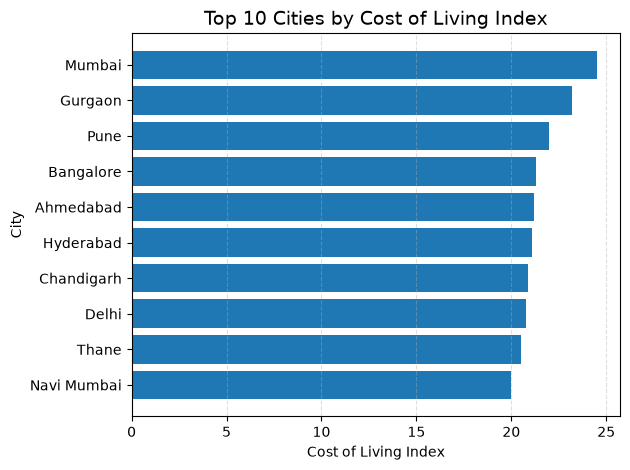

In [53]:

# Select the top 10 cities
top_10_cities = city_clean.nlargest(
    10, "Cost of Living Index"
).sort_values("Cost of Living Index", ascending=True)

# Create the chart

plt.barh(
    top_10_cities["City"],
    top_10_cities["Cost of Living Index"]
)

plt.title("Top 10 Cities by Cost of Living Index", fontsize=14)
plt.xlabel("Cost of Living Index")
plt.ylabel("City")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the chart
chart_path = os.path.join(
    output_folder, "top_10_cost_of_living.png"
)
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

+ A horizontal bar chart showing the 10 cities with the highest Cost of Living Index.
+ City names on the vertical axis.
+ Index values on the horizontal axis.
+ A PNG image saved in your outputs\charts folder.

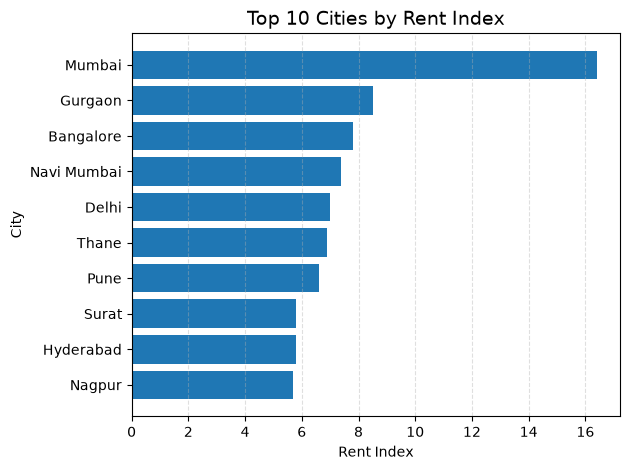

In [54]:

# Select the top 10 cities by Rent Index
top_10_rent = city_clean.nlargest(
    10, "Rent Index"
).sort_values("Rent Index", ascending=True)

# Create the chart

plt.barh(
    top_10_rent["City"],
    top_10_rent["Rent Index"]
)

plt.title("Top 10 Cities by Rent Index", fontsize=14)
plt.xlabel("Rent Index")
plt.ylabel("City")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the chart
chart_path = os.path.join(
    output_folder, "top_10_rent_index.png"
)
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

It tells us about
+ Which cities have the highest rent index.
+ How rental costs differ among the top 10 cities.
+ Whether the most expensive cities overall also rank highly for rent.

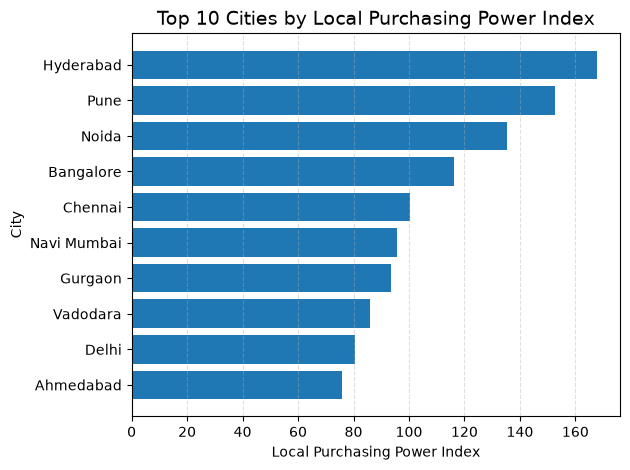

In [55]:

# Select the top 10 cities by purchasing power
top_10_purchasing = city_clean.nlargest(
    10, "Local Purchasing Power Index"
).sort_values(
    "Local Purchasing Power Index",
    ascending=True
)

# Create the chart

plt.barh(
    top_10_purchasing["City"],
    top_10_purchasing["Local Purchasing Power Index"]
)

plt.title(
    "Top 10 Cities by Local Purchasing Power Index",
    fontsize=14
)
plt.xlabel("Local Purchasing Power Index")
plt.ylabel("City")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the chart
chart_path = os.path.join(
    output_folder, "top_10_purchasing_power.png"
)
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

+ Which cities rank highest in local purchasing power.
+ How purchasing power varies between cities.
+ Why a city with a high cost-of-living index may still have relatively high purchasing power.

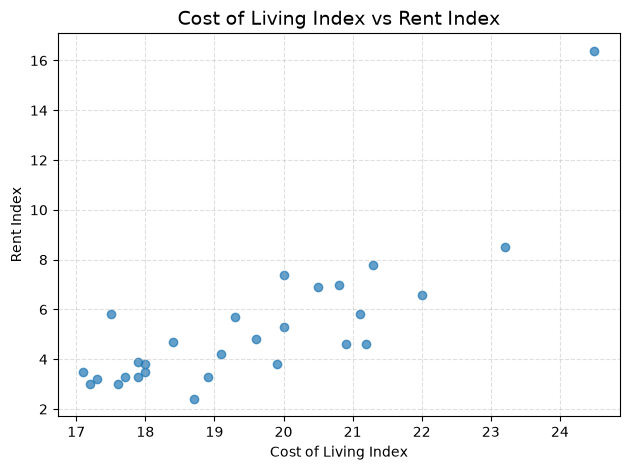

In [56]:

# Create the scatter plot

plt.scatter(
    city_clean["Cost of Living Index"],
    city_clean["Rent Index"],
    alpha=0.7
)

plt.title(
    "Cost of Living Index vs Rent Index",
    fontsize=14
)
plt.xlabel("Cost of Living Index")
plt.ylabel("Rent Index")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the chart
chart_path = os.path.join(
    output_folder, "cost_of_living_vs_rent.png"
)
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

+ Each dot represents one city.
+ The horizontal axis shows the Cost of Living Index.
+ The vertical axis shows the Rent Index.
+ Dots toward the upper-right indicate cities with higher values on both indices.
+ A visible upward pattern suggests a positive relationship, but the chart alone doesn't establish causation.

In [57]:

# Calculate Pearson correlation
correlation = city_clean[
    ["Cost of Living Index", "Rent Index"]
].corr().iloc[0, 1]

print(
    "Correlation between Cost of Living Index and Rent Index:",
    round(correlation, 3)
)

# Interpret the result
if correlation > 0.7:
    print("Interpretation: Strong positive relationship.")
elif correlation > 0.3:
    print("Interpretation: Moderate positive relationship.")
elif correlation > 0:
    print("Interpretation: Weak positive relationship.")
elif correlation < -0.7:
    print("Interpretation: Strong negative relationship.")
elif correlation < -0.3:
    print("Interpretation: Moderate negative relationship.")
elif correlation < 0:
    print("Interpretation: Weak negative relationship.")
else:
    print("Interpretation: No linear correlation.")


Correlation between Cost of Living Index and Rent Index: 0.81
Interpretation: Strong positive relationship.


#### Cost of Living vs Groceries Index: Top 10 Cities

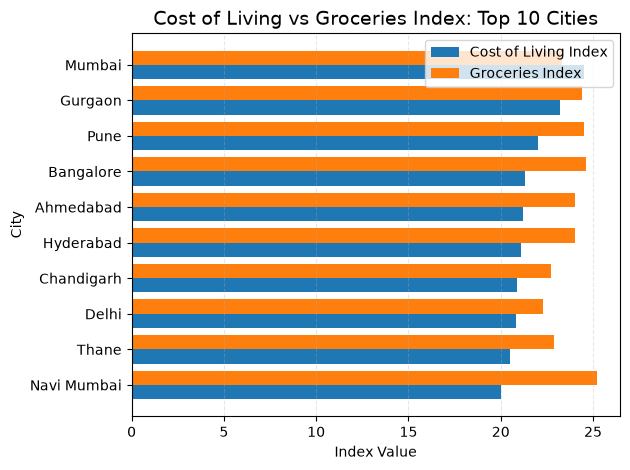

In [58]:

# Select the top 10 cities by Cost of Living Index
top_cities = city_clean.nlargest(
    10, "Cost of Living Index"
).sort_values(
    "Cost of Living Index",
    ascending=True
)

# Set up positions and bar width
import numpy as np

y = np.arange(len(top_cities))
bar_width = 0.4


# Plot both indices
plt.barh(
    y - bar_width / 2,
    top_cities["Cost of Living Index"],
    bar_width,
    label="Cost of Living Index"
)

plt.barh(
    y + bar_width / 2,
    top_cities["Groceries Index"],
    bar_width,
    label="Groceries Index"
)

plt.yticks(y, top_cities["City"])
plt.title(
    "Cost of Living vs Groceries Index: Top 10 Cities",
    fontsize=14
)
plt.xlabel("Index Value")
plt.ylabel("City")
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

# Save the chart
chart_path = os.path.join(
    output_folder, "cost_of_living_vs_groceries.png"
)
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

+ How grocery costs compare with the overall cost-of-living index.
+ Which cities have relatively higher or lower grocery index values.
+ Whether grocery costs appear to contribute to differences in the overall index.

#### Top 10 Cities by Restaurant Price Index

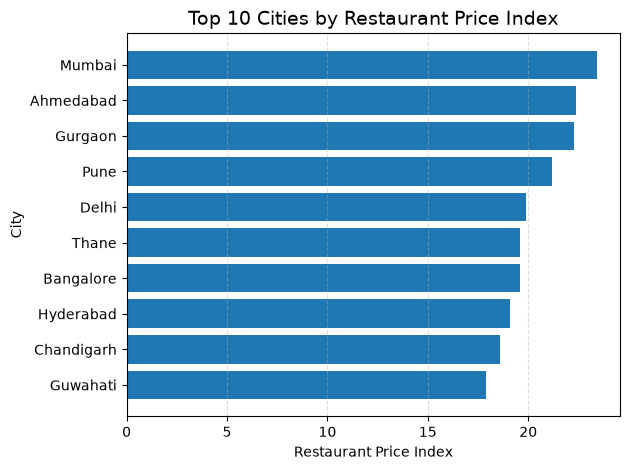

In [59]:

# Select the top 10 cities by Restaurant Price Index
top_10_restaurants = city_clean.nlargest(
    10, "Restaurant Price Index"
).sort_values(
    "Restaurant Price Index",
    ascending=True
)

# Create horizontal bar chart

plt.barh(
    top_10_restaurants["City"],
    top_10_restaurants["Restaurant Price Index"]
)

plt.title(
    "Top 10 Cities by Restaurant Price Index",
    fontsize=14
)
plt.xlabel("Restaurant Price Index")
plt.ylabel("City")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save chart
chart_path = os.path.join(
    output_folder, "top_10_restaurant_price_index.png"
)
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

+ Which cities have the highest restaurant price index.
+ How restaurant prices vary across cities.
+ How restaurant costs compare with grocery costs in your other visualizations.

#### Distribution of Cost of Living Index Across Cities

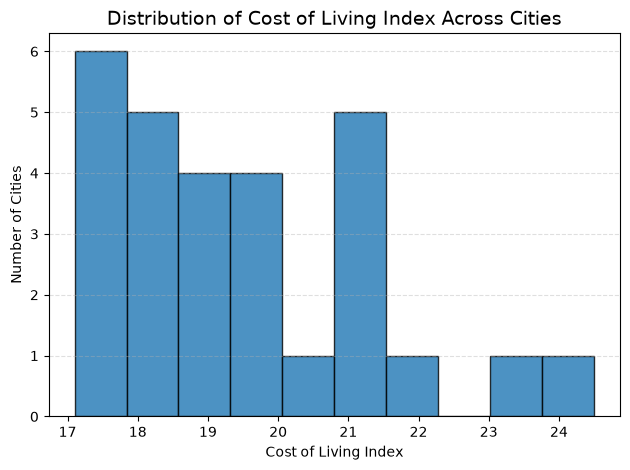

In [60]:

# Create a histogram of the Cost of Living Index
plt.hist(
    city_clean["Cost of Living Index"].dropna(),
    bins=10,
    edgecolor="black",
    alpha=0.8
)

plt.title("Distribution of Cost of Living Index Across Cities",
          fontsize=14)
plt.xlabel("Cost of Living Index")
plt.ylabel("Number of Cities")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the chart
chart_path = os.path.join(
    output_folder, "cost_of_living_distribution.png"
)
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()


+ X-axis: ranges of Cost of Living Index values.
+ Y-axis: number of cities within each range.
+ Taller bars indicate more cities in that range.
+ A wide spread suggests greater variation in the index across cities.

#### Summary Statistics of Cost-of-Living Indices

+ Mean: average index value across the cities.
+ Median: middle value.
+ Standard deviation: how much the values vary.
+ Minimum and maximum: lowest and highest index values.
+ 25%, 50%, and 75% quartiles: how the values are distributed.

#### Correlation Heatmap of Cost-of-Living Indices

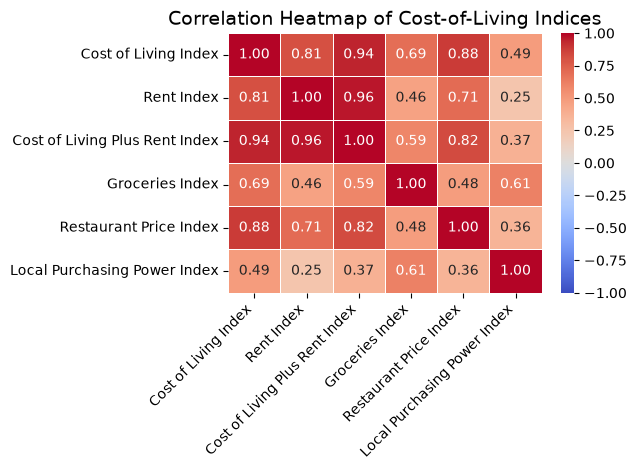

In [62]:

import seaborn as sns

# Select the index columns
index_columns = [
    "Cost of Living Index",
    "Rent Index",
    "Cost of Living Plus Rent Index",
    "Groceries Index",
    "Restaurant Price Index",
    "Local Purchasing Power Index"
]

# Calculate the correlation matrix
correlation_matrix = city_clean[index_columns].corr()

# Create the heatmap

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Cost-of-Living Indices",
          fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save the chart
chart_path = os.path.join(
    output_folder, "cost_of_living_correlation_heatmap.png"
)
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

+ +1: perfect positive linear correlation.
+ Near 0: little linear correlation.
+ −1: perfect negative linear correlation.
+ The diagonal will show 1.00 because each index is perfectly correlated with itself.

#### Average Item Price by Category in India

In [61]:

# Select the main index columns
index_columns = [
    "Cost of Living Index",
    "Rent Index",
    "Cost of Living Plus Rent Index",
    "Groceries Index",
    "Restaurant Price Index",
    "Local Purchasing Power Index"
]

# Calculate summary statistics
summary_stats = city_clean[index_columns].describe().round(2)

print("Summary Statistics of Cost-of-Living Indices")
display(summary_stats)

# Calculate the average for each index
print("\nAverage Index Values:")
display(
    city_clean[index_columns]
    .mean()
    .sort_values(ascending=False)
    .round(2)
    .rename("Average Index")
    .to_frame()
)

# Save summary statistics
summary_path = os.path.join(
    project_folder, "outputs", "cost_of_living_summary_statistics.csv"
)

summary_stats.to_csv(summary_path)

Summary Statistics of Cost-of-Living Indices


,Cost of Living Index,Rent Index,Cost of Living Plus Rent Index,Groceries Index,Restaurant Price Index,Local Purchasing Power Index
count,28.00,28.00,28.00,28.00,28.00,28.00
mean,19.49,5.22,12.88,22.29,16.66,77.06
std,1.90,2.74,2.19,1.62,3.26,31.92
min,17.10,2.40,10.60,19.60,11.50,41.00
25%,17.90,3.45,11.28,20.90,14.20,59.10
50%,19.20,4.60,12.30,22.25,15.50,62.90
75%,20.82,6.00,14.05,23.85,19.23,87.92
max,24.50,16.40,20.80,25.20,23.40,167.70



Average Index Values:


,Average Index
Local Purchasing Power Index,77.06
Groceries Index,22.29
Cost of Living Index,19.49
Restaurant Price Index,16.66
Cost of Living Plus Rent Index,12.88
Rent Index,5.22


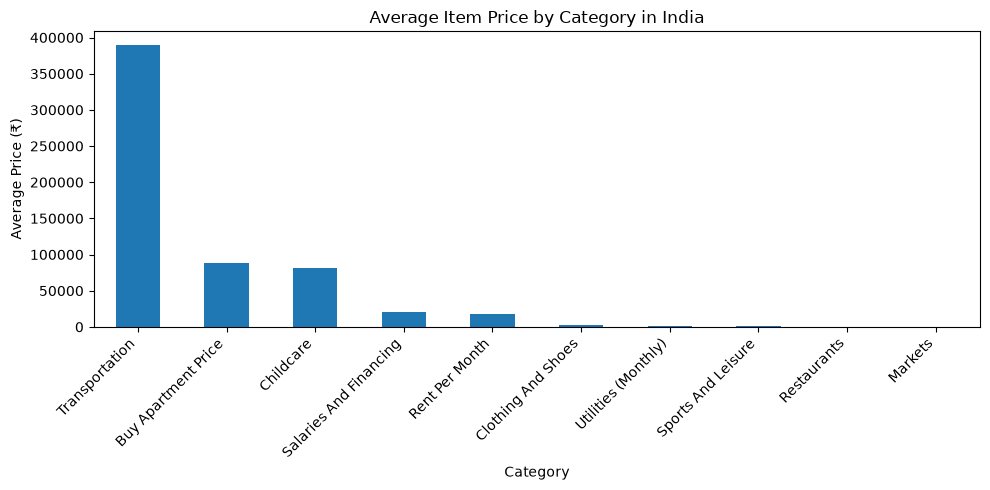

In [77]:
category_prices = (
    prices.groupby("Category")["Price"]
    .mean()
    .sort_values(ascending=False)
)

category_prices.plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Item Price by Category in India"
)

plt.xlabel("Category")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### City-wise Item Price Comparison

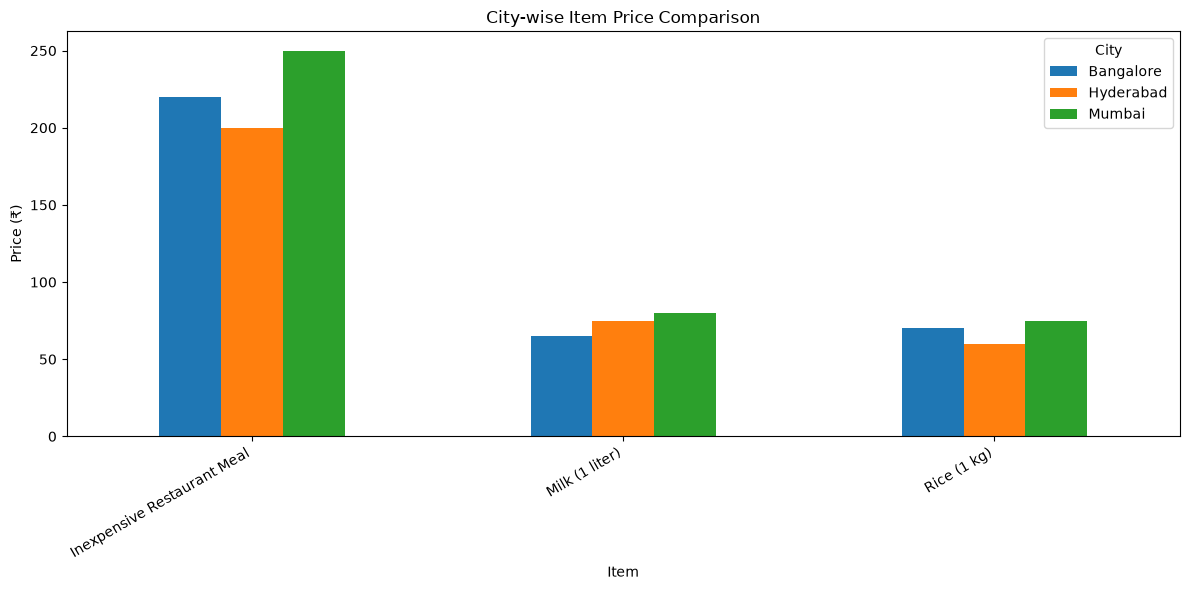

In [83]:
import pandas as pd
import matplotlib.pyplot as plt

prices = pd.read_csv(
    "data/processed/numbeo_city_item_prices.csv"
)

comparison = prices.pivot(
    index="Item",
    columns="City",
    values="Price"
)

comparison.plot(kind="bar", figsize=(12, 6))

plt.title("City-wise Item Price Comparison")
plt.xlabel("Item")
plt.ylabel("Price (₹)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="City")
plt.tight_layout()
plt.show()

In [79]:
# Calculate the average of each index
index_columns = [
    "Cost of Living Index",
    "Rent Index",
    "Cost of Living Plus Rent Index",
    "Groceries Index",
    "Restaurant Price Index",
    "Local Purchasing Power Index"
]

average_indices = city_clean[index_columns].mean().round(2)

print("Average Values Across Cities:")
display(average_indices.rename("Average Index").to_frame())

# Find the five cities with the highest cost of living
top_5_cities = city_clean.nlargest(
    5, "Cost of Living Index"
)[["City", "Cost of Living Index", "Rent Index",
   "Groceries Index", "Local Purchasing Power Index"]]

print("\nTop 5 Cities by Cost of Living Index:")
display(top_5_cities.reset_index(drop=True))

# Find the five cities with the lowest cost of living
bottom_5_cities = city_clean.nsmallest(
    5, "Cost of Living Index"
)[["City", "Cost of Living Index", "Rent Index",
   "Groceries Index", "Local Purchasing Power Index"]]

print("\nBottom 5 Cities by Cost of Living Index:")
display(bottom_5_cities.reset_index(drop=True))

# Save the findings
findings_path = os.path.join(
    project_folder, "outputs", "key_city_findings.csv"
)

top_5_cities.assign(Ranking="Top 5").to_csv(
    findings_path, index=False
)

Average Values Across Cities:


,Average Index
Cost of Living Index,19.49
Rent Index,5.22
Cost of Living Plus Rent Index,12.88
Groceries Index,22.29
Restaurant Price Index,16.66
Local Purchasing Power Index,77.06



Top 5 Cities by Cost of Living Index:


,City,Cost of Living Index,Rent Index,Groceries Index,Local Purchasing Power Index
0,Mumbai,24.5,16.4,23.3,69.4
1,Gurgaon,23.2,8.5,24.4,93.4
2,Pune,22.0,6.6,24.5,152.7
3,Bangalore,21.3,7.8,24.6,116.2
4,Ahmedabad,21.2,4.6,24.0,75.8



Bottom 5 Cities by Cost of Living Index:


,City,Cost of Living Index,Rent Index,Groceries Index,Local Purchasing Power Index
0,Coimbatore,17.1,3.5,20.8,71.7
1,Bhopal,17.2,3.0,21.8,59.2
2,Lucknow (Lakhnau),17.3,3.2,19.9,59.8
3,Surat,17.5,5.8,20.9,49.5
4,Rajkot,17.6,3.0,22.2,44.9


In [80]:

import pandas as pd
from scipy.stats import pearsonr

# Load the cleaned dataset
df = pd.read_csv("data/processed/numbeo_india_city_indices.csv")

# Select required columns and convert to numeric
data = df[["Cost of Living Index", "Rent Index"]].copy()

data["Cost of Living Index"] = pd.to_numeric(
    data["Cost of Living Index"], errors="coerce"
)
data["Rent Index"] = pd.to_numeric(
    data["Rent Index"], errors="coerce"
)

# Remove missing and infinite values
import numpy as np

data = data.replace([np.inf, -np.inf], np.nan).dropna()

# Hypothesis testing
alpha = 0.05

# H0: There is no linear correlation between the two indices.
# H1: There is a linear correlation between the two indices.

correlation, p_value = pearsonr(
    data["Cost of Living Index"],
    data["Rent Index"]
)

print("Hypothesis Testing: Cost of Living vs Rent")
print("-" * 45)
print("Number of cities:", len(data))
print(f"Pearson correlation: {correlation:.4f}")
print(f"P-value: {p_value:.6f}")
print("Significance level:", alpha)

if p_value < alpha:
    print("Decision: Reject the null hypothesis (H0).")
    print("Conclusion: There is a statistically significant")
    print("linear relationship between the two indices.")
else:
    print("Decision: Fail to reject the null hypothesis (H0).")
    print("Conclusion: There is insufficient evidence of a")
    print("statistically significant linear relationship.")


Hypothesis Testing: Cost of Living vs Rent
---------------------------------------------
Number of cities: 28
Pearson correlation: 0.8099
P-value: 0.000000
Significance level: 0.05
Decision: Reject the null hypothesis (H0).
Conclusion: There is a statistically significant
linear relationship between the two indices.


## Hypothesis
- H₀ (Null hypothesis): There is no linear correlation between the Cost of Living Index and Rent Index.
- H₁ (Alternative hypothesis): There is a linear correlation between the Cost of Living Index and Rent Index.
#### Interpretation
1. The correlation coefficient of 0.8099 indicates a strong positive linear relationship.
2. The p-value is below the significance level of 0.05.
3. Therefore, we reject the null hypothesis.
4. The data provides statistically significant evidence of a linear relationship between rent and cost of living.

## Conclusion

The **India City-wise Cost of Living Analysis** project uses Numbeo data and Python libraries such as Pandas, Matplotlib, and Seaborn to examine differences in cost-of-living indexes, rent indexes, groceries, restaurant prices, and local purchasing power across 28 Indian cities.

The analysis includes data cleaning, exploratory data analysis, city and state/region comparisons, KPI calculations, bar charts, a correlation heatmap, and scatter plots. The results identify differences between cities and help illustrate how living costs and purchasing power can be compared.

The findings can support preliminary budgeting, relocation planning, and further cost-of-living research. However, the dataset covers only the cities collected, and its index values should not be interpreted as actual monthly expenses or representative estimates for every state.

## Business recommendations
These are recommendations your analysis can support, with appropriate limitations:
1. Relocation planning: Compare cost-of-living and rent indexes before choosing a city for employment or education.
2. Budget planning: Investigate cities with lower cost indexes when evaluating possible living locations.
3. Salary comparisons: Consider local purchasing power alongside salary offers rather than comparing salaries alone.
4. Housing decisions: Use rent-index comparisons as an initial guide, then examine actual property rents.
5. Further research: Collect more cities per state before drawing broader state-level conclusions.
